# Instrument responses for SmartSolo nodes

An instrument response describes how ground motion becomes the numbers in a data file. For a SmartSolo IGU-16HR 3C, ground velocity becomes volts in a 5 Hz geophone, which a preamplifier (0–36 dB) scales. A 24-bit ADC then turns the volts into counts, and digital anti-alias (FIR) filters decimate the result to the recording rate. To get ground velocity back you divide by this response (`remove_response` in ObsPy), so the response has to be right in amplitude and phase.

This notebook shows:

1. the physics of the DT-SOLO geophone and where the published numbers come from;
2. the response models in [`instrument_responses/`](../../instrument_responses/) and how they differ;
3. preamp gain: decibels against powers of two;
4. the anti-alias FIR filters, linear against minimum phase;
5. how temperature changes the geophone response;
6. what the choice of model does to real data;
7. how to add a model.

Responses are stored as **FDSN StationXML**, the standard format for station metadata and responses ([FDSN StationXML documentation](https://docs.fdsn.org/projects/stationxml/en/latest/)), with a readable `response.yaml` beside each model. `smartsolo_response.inspect_instrument_response` gives a quick look at any of them.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "../../lib")
import smartsolo_response as sr, smartsolo_node as sn, smartsolo_dld as dld
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:.6g}")

## 1. The DT-SOLO geophone

The sensor is a moving-coil geophone. A coil on a spring-mounted mass moves in a magnetic field and produces a voltage proportional to velocity above the natural frequency f0. Below f0 the output falls as f². In the Laplace domain:

H(s) = G · s² / (s² + 2hω₀s + ω₀²),  with ω₀ = 2πf₀,

which has two zeros at the origin and a pole pair at −hω₀ ± iω₀√(1−h²).

The [SmartSolo IGU-16HR 3C data sheet](https://smartsolo.com/sc/IGU-16HR%203C.pdf) gives the following values for the DT-SOLO 5 Hz sensor:
- f₀ = 5 Hz;
- coil resistance 1850 Ω;
- open-circuit damping 0.60, and 0.70 with a 43 kΩ shunt;
- open-circuit sensitivity 80 V/(m/s).

The shunt resistor across the coil adds electrical damping and lowers the sensitivity by a voltage divider:

In [2]:
G0, Rc, Rs, f0, h_open, h_shunt = 80.0, 1850.0, 43000.0, 5.0, 0.60, 0.70
G = G0 * Rs / (Rs + Rc)
w0 = 2 * np.pi * f0
# electrical damping h_e = G0^2 / (2 m w0 (Rc + Rs)) -> moving mass implied by the data sheet
m_mass = G0 ** 2 / (2 * w0 * (Rc + Rs) * (h_shunt - h_open))
print(f"shunted sensitivity  {G:.2f} V/(m/s)   (NRL: 76.6, AusPass page: 76.7)")
print(f"implied moving mass  {1000 * m_mass:.1f} g")
p = sn.AUSPASS_16HR3C["poles"][0]
print(f"AusPass poles {p:.6f}: f0 = {abs(p) / 2 / np.pi:.4f} Hz, h = {-p.real / abs(p):.4f}")

shunted sensitivity  76.70 V/(m/s)   (NRL: 76.6, AusPass page: 76.7)
implied moving mass  22.7 g
AusPass poles -22.211059+22.217768j: f0 = 5.0000 Hz, h = 0.7070


So the published poles (AusPass, NRL: −22.2111 ± 22.2178i) describe a 5.000 Hz geophone with h = 0.707, critical damping by design, a little above the data sheet's 0.70. The 76.6 V/(m/s) used by the NRL and the harvest script is the shunted sensitivity.

A huddle test of 24 nodes beside a permanent station found that estimated poles "strongly converge" on the manufacturer's values, and that the manufacturer response restores ground velocity correctly ([Zeckra, Van Noten & Lecocq 2022, EarthArXiv](https://doi.org/10.31223/X5F073)).

**The ADC.** The input range is ±2.5 V at 0 dB ([data sheet](https://smartsolo.com/sc/IGU-16HR%203C.pdf)). A 24-bit output therefore gives 2²³ counts / 2.5 V = 3 355 443 counts/V. This is the "3355.4428 counts/mV" of the manual, the 3 355 440 of the NRL and the 3 355 500 of the DTCC data-sheet constants.

In [3]:
print(f"2^23 / 2.5 V = {2**23 / 2.5:,.1f} counts/V")
print(f"AusPass overall 257 019 225.55 / 76.6 = {257019225.55108312 / 76.6:,.1f} counts/V")

2^23 / 2.5 V = 3,355,443.2 counts/V
AusPass overall 257 019 225.55 / 76.6 = 3,355,342.4 counts/V


## 2. The response models
Each folder of `instrument_responses/` is one model; `response.yaml` says where it comes from.

In [4]:
sr.list_responses()

,model,title,default,devices,gains_db,sample_rates,filter_phases,n_files,use
0,auspass,AusPass / ANSIR published SmartSolo response (...,True,"[BD3C-5, IGU-16HR3C]","[0, 6, 12, 18, 24, 30, 36]",any,-,9,"Default. Published, huddle-tested response for..."
1,dtcc,DTCC data-sheet constants (as in the harvest s...,False,[IGU-16HR3C],"[0, 6, 12, 18, 24, 30, 36]",any,-,7,For comparison with archives made by the harve...
2,nominal,DT-SOLO 5 Hz data-sheet geophone,False,[IGU-16HR3C],"[0, 6, 12, 18, 24, 30, 36]",any,-,7,A textbook geophone from the data sheet; usefu...
3,nrl,EarthScope (IRIS) Nominal Response Library: DT...,False,"[BD3C-5, IGU-16HR3C]","[0, 6, 12, 18, 24, 30, 36]","[50, 100, 125, 250, 500, 1000]","[LP, MP]",100,The manufacturer-supplied nominal response wit...


IGU-16HR 3C 5Hz, 0 dB preamp gain in the data, 1000 sps, linear phase
model                      auspass         dtcc     nominal         nrl
sensitivity            2.55456e+08  2.55468e+08 2.67381e+08 2.57099e+08
sensitivity_freq_hz             15           15          15         210
input_units                    M/S          M/S         M/S         m/s
output_units                COUNTS       COUNTS      COUNTS       count
n_stages                         3            3           3           7
n_fir_stages                     0            0           0           4
f0_hz                            5            5           5     5.00001
damping                      0.707        0.707         0.7       0.707
flat_gain              2.57011e+08  2.57023e+08 2.68449e+08  2.5702e+08
gain_1Hz_rel_flat_db       -27.965      -27.965    -27.9589    -27.9647
gain_2Hz_rel_flat_db      -16.0263     -16.0263    -16.0002     -16.026
gain_5Hz_rel_flat_db      -3.00898     -3.00898    -2.92329    -3.

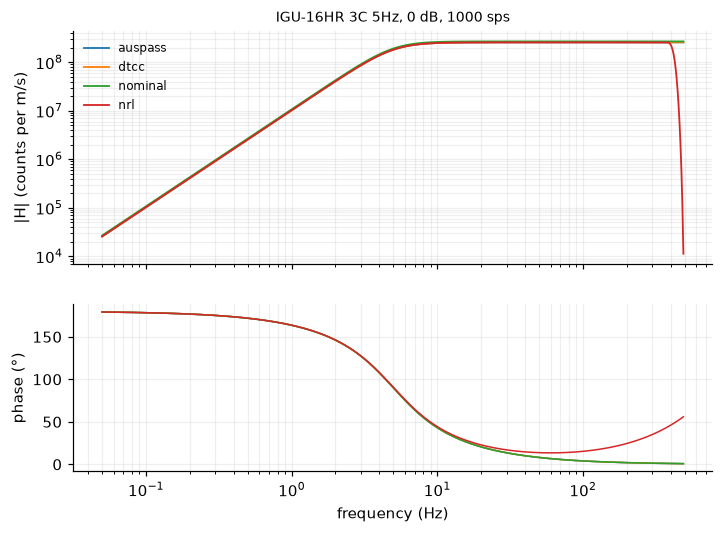

In [5]:
table, fig = sr.inspect_instrument_response(["auspass", "dtcc", "nominal", "nrl"], gain_db=0, sampling_rate=1000)

The default `auspass` is the response AusPass publishes after huddle tests ([AusPass, SmartSolo Node Seismometers](https://auspass.edu.au/xwiki/bin/view/Instrumentation/SmartSolo%20Nodes/)). Its overall sensitivity is 257 019 226 counts/(m/s) for counts with the gain removed and the polarity inverted. The models compare as follows:

- **`dtcc`** is 0.005 % more sensitive than `auspass`.
- **`nrl`** has the same poles and passband gain to 0.003 %, and adds the digital filter chain.
- **`nominal`** mixes the open-circuit sensitivity with the shunted damping, as the data sheet lists them, so its sensitivity is about 4.4 % high.

The differences show more clearly relative to `auspass`:

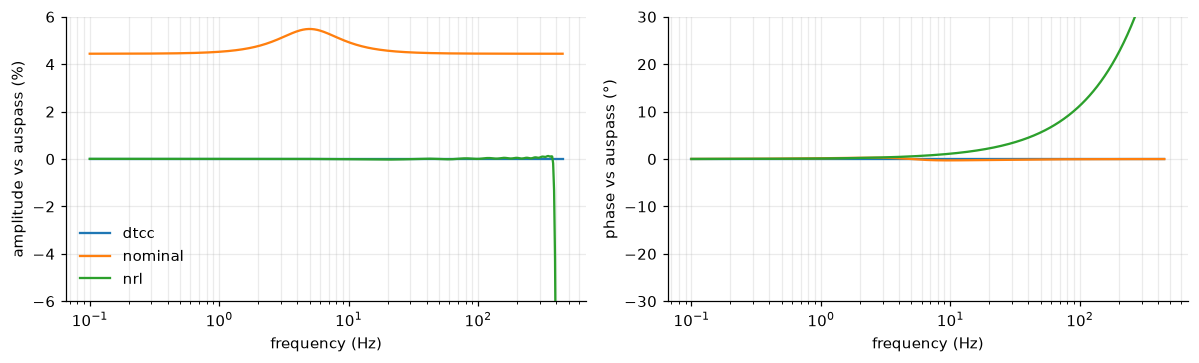

In [6]:
f = np.logspace(-1, np.log10(450), 500)
ref = sr.response_curve(sr.get_response("auspass", sampling_rate=1000), f)[1]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for m in ["dtcc", "nominal", "nrl"]:
    hh = sr.response_curve(sr.get_response(m, sampling_rate=1000), f)[1]
    ax[0].semilogx(f, 100 * (np.abs(hh) / np.abs(ref) - 1), label=m)
    ax[1].semilogx(f, np.degrees(np.angle(hh / ref)), label=m)
ax[0].set(xlabel="frequency (Hz)", ylabel="amplitude vs auspass (%)", ylim=(-6, 6))
ax[1].set(xlabel="frequency (Hz)", ylabel="phase vs auspass (°)", ylim=(-30, 30))
ax[0].legend(frameon=False); [a.grid(alpha=.25, which="both") for a in ax]; fig.tight_layout()

Near Nyquist the `nrl` curve departs from the others: those are the anti-alias FIR filters, which the other models leave out (section 4). Below a few Hz all models agree to within their sensitivity offsets, because they share the geophone poles.

## 3. Preamp gain: decibels or powers of two?
SoloLite, the AusPass instructions and node_toolbox treat the gain as 10^(dB/20); for example, 24 dB is removed by dividing by 15.848932. The NRL, however, describes the IGU-16 preamp as "gain factors 1, 2, 4, 8, 16, 32 or 64" ([NRL, DTCC SmartSolo-IGU-16](https://ds.iris.edu/ds/nrl/datalogger/dtcc/smartsolo-igu-16/)): steps of 6.02 dB. The two readings differ by up to 1.4 %:

In [7]:
g = np.array(sr.GAINS_DB)
nrl = np.array([sr.get_response("nrl", gain_db=x, sampling_rate=1000).instrument_sensitivity.value for x in g])
aus = np.array([sr.get_response("auspass", gain_db=x, sampling_rate=1000).instrument_sensitivity.value for x in g])
pd.DataFrame({"gain_dB": g, "10^(dB/20)": 10 ** (g / 20), "2^(dB/6)": 2.0 ** (g / 6),
              "NRL / AusPass overall": nrl / aus * aus[0] / nrl[0],
              "difference_%": 100 * (2.0 ** (g / 6) / 10 ** (g / 20) - 1)}).round(5)

,gain_dB,10^(dB/20),2^(dB/6),NRL / AusPass overall,difference_%
0,0,1,1,1,0
1,6,1.99526,2,1.00238,0.23745
2,12,3.98107,4,1.00476,0.47546
3,18,7.94328,8,1.00714,0.71403
4,24,15.8489,16,1.00953,0.95318
5,30,31.6228,32,1.01193,1.19289
6,36,63.0957,64,1.01434,1.43316


Which reading is right can only be settled by recording the same ground motion at different gains, side by side. Until then, removing the gain with 10^(dB/20) (as SoloLite does) leaves an amplitude uncertainty of up to 1.4 % at 36 dB. This is small for most work, but not for magnitude or calibration studies.

## 4. Anti-alias filters: linear or minimum phase
The ADC samples at a high rate. FIR stages then filter and decimate to the recording rate. The NRL chain for the IGU-16HR 3C starts at 32 kHz, and has four decimating FIR stages at 1000 sps. The script's `Anti_Alias_Filter` selects linear phase (2, the default) or minimum phase (1). The data sheet puts the corner at 82.6 % of Nyquist (206.5 Hz at 2 ms).

In [8]:
r = sr.get_response("nrl", sampling_rate=1000)
pd.DataFrame([dict(stage=s.stage_sequence_number, type=type(s).__name__, input=s.input_units, output=s.output_units,
                   gain=s.stage_gain, input_rate=s.decimation_input_sample_rate, factor=s.decimation_factor,
                   delay_s=s.decimation_delay, correction_s=s.decimation_correction,
                   n_coefficients=len(getattr(s, "numerator", []) or [])) for s in r.response_stages])

,stage,type,input,output,gain,input_rate,factor,delay_s,correction_s,n_coefficients
0,1,PolesZerosResponseStage,m/s,V,76.6,NaN,NaN,NaN,NaN,0
1,2,PolesZerosResponseStage,V,V,1,NaN,NaN,NaN,NaN,0
2,3,CoefficientsTypeResponseStage,V,count,3.35544e+06,32000,1,0,0,1
3,4,CoefficientsTypeResponseStage,count,count,1,32000,2,0.00015625,0.00015625,11
4,5,CoefficientsTypeResponseStage,count,count,1,16000,2,0.0004375,0.0004375,15
5,6,CoefficientsTypeResponseStage,count,count,1,8000,4,0.0031875,0.0031875,52
6,7,CoefficientsTypeResponseStage,count,count,1,2000,2,0.02725,0.02725,110


,rate,phase,corner_hz,corner_pct_nyquist,filter_delay_ms_mean,filter_delay_ms_spread
0,100,linear,41.3,82.6,-3.12,0
1,100,minimum,41.37,82.74,-9.68,25.51
2,250,linear,103.23,82.58,-1.25,0
3,250,minimum,103.41,82.73,-3.88,10.18
4,1000,linear,412.88,82.58,-0.31,0
5,1000,minimum,413.63,82.73,-0.97,2.55


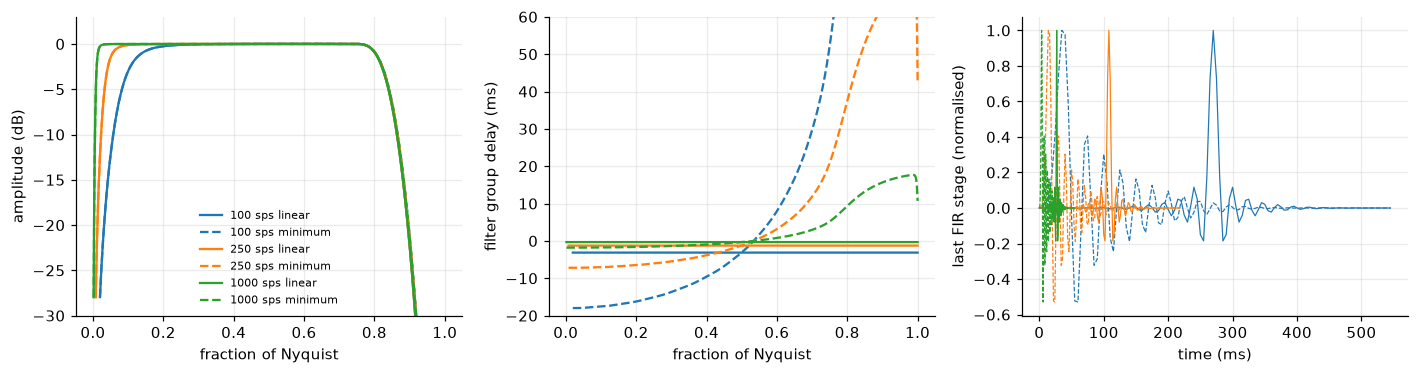

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
rows = []
for rate, c in zip([100, 250, 1000], ["C0", "C1", "C2"]):
    for ph, ls in [("linear", "-"), ("minimum", "--")]:
        resp = sr.get_response("nrl", sampling_rate=rate, filter_phase=ph)
        ff = np.linspace(1, 0.5 * rate, 2000)
        hh = resp.get_evalresp_response_for_frequencies(ff)
        a = np.abs(hh) / np.abs(hh[np.argmin(abs(ff - 0.2 * rate))])
        gd = -np.gradient(np.unwrap(np.angle(hh)), 2 * np.pi * ff)
        geo = sr.get_response("auspass", sampling_rate=rate).get_evalresp_response_for_frequencies(ff)
        gd0 = -np.gradient(np.unwrap(np.angle(geo)), 2 * np.pi * ff)
        ax[0].plot(ff / (0.5 * rate), 20 * np.log10(a), ls, color=c, label=f"{rate} sps {ph}")
        ax[1].plot(ff / (0.5 * rate), 1000 * (gd - gd0), ls, color=c)
        hi = (ff > 0.2 * rate) & (a < 1 / np.sqrt(2))
        corner = ff[hi][0] if hi.any() else np.nan
        sel = (ff > 0.05 * rate) & (ff < 0.3 * rate)
        rows.append(dict(rate=rate, phase=ph, corner_hz=corner, corner_pct_nyquist=100 * corner / (0.5 * rate),
                         filter_delay_ms_mean=1000 * np.mean((gd - gd0)[sel]), filter_delay_ms_spread=1000 * np.ptp((gd - gd0)[sel])))
ax[0].set(xlabel="fraction of Nyquist", ylabel="amplitude (dB)", ylim=(-30, 3)); ax[0].legend(fontsize=7, frameon=False)
ax[1].set(xlabel="fraction of Nyquist", ylabel="filter group delay (ms)", ylim=(-20, 60))
for rate, c in zip([100, 250, 1000], ["C0", "C1", "C2"]):
    for ph, ls in [("linear", "-"), ("minimum", "--")]:
        resp = sr.get_response("nrl", sampling_rate=rate, filter_phase=ph)
        fir = [s for s in resp.response_stages if len(getattr(s, "numerator", []) or []) > 1][-1]
        b = np.array(fir.numerator, float); t = np.arange(len(b)) / fir.decimation_input_sample_rate
        ax[2].plot(1000 * t, b / np.abs(b).max(), ls, color=c, lw=0.8)
ax[2].set(xlabel="time (ms)", ylabel="last FIR stage (normalised)")
[a.grid(alpha=.25) for a in ax]; fig.tight_layout()
pd.DataFrame(rows).round(2)

Read the table and figure as follows:

- **Corner.** The −3 dB corner (`corner_pct_nyquist`) lies close to the 82.6 % of Nyquist in the data sheet.
- **Linear phase.** These filters delay all frequencies equally. Their delay is listed in the StationXML (`decimation_delay`) and is also listed as already corrected (`decimation_correction`), so the time stamps should not be shifted. After those corrections the NRL metadata leave a constant residual of about −0.31 samples: −3.1 ms at 100 sps, −0.3 ms at 1000 sps, with no spread across the band. Whether the nodes apply exactly the listed correction is a question for a timing test against a reference station.
- **Minimum phase.** These filters have no pre-echo (their energy comes first), but their group delay depends on frequency. After the listed corrections it averages −9.7 ms at 100 sps, −3.9 ms at 250 sps and −1.0 ms at 1000 sps. Between 5 and 30 % of Nyquist it varies by 25, 10 and 2.6 ms respectively. Minimum-phase recordings therefore change waveform shape and shift picks by a fraction of a sample to a few samples. Use the matching NRL file (`filter_phase="minimum"`) when removing the response, or record with linear phase.
- **Phase convention.** ObsPy's evalresp treats the delay as corrected, so the curves show only the frequency-dependent part.

## 5. Temperature
The coil is copper, so its resistance rises by about 0.39 % per °C. The boot tests in this repository show about 1620 Ω at −2 °C and about 1780 Ω when warm. A higher coil resistance reduces the shunt divider and the electrical damping, which changes both sensitivity and damping:

In [10]:
T = np.array([-40, -20, 0, 20, 40])
Rc_T = 1850 * (1 + 0.00393 * (T - 22))                      # data sheet value at +22 °C
G_T = G0 * Rs / (Rs + Rc_T)
h_T = h_open + G0 ** 2 / (2 * m_mass * w0 * (Rc_T + Rs))
pd.DataFrame({"T_C": T, "coil_ohm": Rc_T, "sensitivity_V_per_m_s": G_T, "sensitivity_change_%": 100 * (G_T / G - 1),
              "damping": h_T}).round(3)

,T_C,coil_ohm,sensitivity_V_per_m_s,sensitivity_change_%,damping
0,-40,1399.23,77.479,1.015,0.701
1,-20,1544.64,77.226,0.686,0.701
2,0,1690.05,76.975,0.358,0.7
3,20,1835.46,76.725,0.032,0.7
4,40,1980.87,76.477,-0.291,0.7


From −40 to +40 °C the shunted sensitivity changes by about 1.3 % (higher in the cold, because the coil's resistance falls), while the electrical part of the damping barely changes. These are far smaller than the model differences above. The mechanical spring and the open-circuit damping also change with temperature, but the data sheet gives no values for them. The boot-time geophone test in each `[DeviceInfo]` measures f0, damping and sensitivity for every power-up; `build_inventory(response="test")` uses them.

## 6. Real data: does the choice matter?
Ten seconds of the break-test data, with the response removed using each model. The figure shows ground velocity, and its ratio to the `auspass` result in the 5–50 Hz band.

auspass        0
dtcc      -0.005
nominal   -4.565
nrl        0.009
Name: RMS difference vs auspass (%), dtype: float64

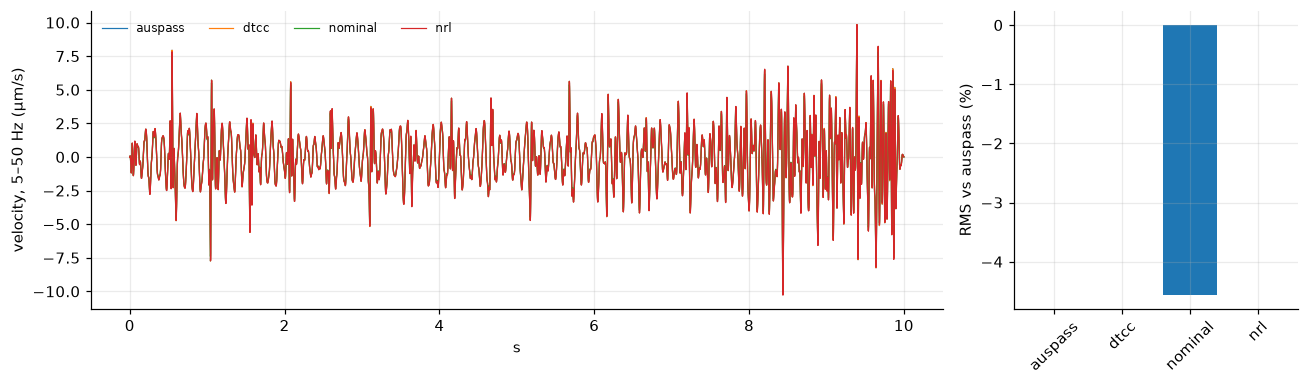

In [11]:
f = next(Path("../../data/break_test/453010047").glob("*/seis000Z.DLD"))
st = dld.read_dld(f)
tr0 = st[0].copy(); tr0.trim(tr0.stats.starttime + 600, tr0.stats.starttime + 610)
tr0.data = -tr0.data.astype(float)                     # IGU-16HR polarity
rate = tr0.stats.sampling_rate
out = {}
for m in ["auspass", "dtcc", "nominal", "nrl"]:
    tr = tr0.copy()
    tr.stats.response = sr.get_response(m, gain_db=0, sampling_rate=rate)
    tr.remove_response(output="VEL", pre_filt=(0.5, 1.0, 0.4 * rate, 0.45 * rate), water_level=60)
    tr.filter("bandpass", freqmin=5, freqmax=50, zerophase=True)
    out[m] = tr
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw=dict(width_ratios=[3, 1]))
t = out["auspass"].times()
for m, tr in out.items():
    ax[0].plot(t, 1e6 * tr.data, lw=0.8, label=m)
ax[0].set(ylabel="velocity, 5–50 Hz (µm/s)", xlabel="s"); ax[0].legend(ncol=4, fontsize=8, frameon=False)
rms = {m: np.sqrt(np.mean(tr.data ** 2)) for m, tr in out.items()}
ax[1].bar(range(len(rms)), [100 * (v / rms["auspass"] - 1) for v in rms.values()], tick_label=list(rms))
ax[1].set_ylabel("RMS vs auspass (%)"); ax[1].tick_params(axis="x", rotation=45)
[a.grid(alpha=.25) for a in ax]; fig.tight_layout()
pd.Series({m: 100 * (v / rms["auspass"] - 1) for m, v in rms.items()}, name="RMS difference vs auspass (%)").round(3)

With the same poles and zeros, `auspass`, `dtcc` and `nrl` give the same velocity to within 0.01 %. `nominal` gives velocities about 4.6 % lower, because its sensitivity is 4.4 % higher.

Always correct with the response that matches what was done to the data:
- **Preamp gain.** Use the gain contained in the counts: the log value for raw DLD, and 0 dB when the gain was removed.
- **Polarity.** Use the polarity convention: node_toolbox multiplies IGU-16HR data by −1, as AusPass does.
- **Filter phase.** For minimum-phase recordings, use `nrl` with `filter_phase="minimum"`.

Below f0 the geophone output falls as f², so removing the response there amplifies noise. Use a `pre_filt` corner well above the band in which the signal is above the sensor noise; for these nodes the data are useful down to about 0.2 Hz ([Zeckra et al. 2022](https://doi.org/10.31223/X5F073)).

## 7. Broadband nodes (BD3C-5)
AusPass publishes a response for the BD3C-5 too, and notes that it fits well above 0.5 Hz but may be somewhat high below its 0.2 Hz corner. The NRL has the DT-SOLO-BB sensor with 209.4 V/(m/s).

IGU-16 BD3C 5s, 0 dB preamp gain in the data, 250 sps, linear phase
model                 auspass BD3C-5  nrl BD3C-5
sensitivity              7.02652e+08 6.91416e+08
sensitivity_freq_hz               10      53.025
input_units                      M/S         m/s
output_units                  COUNTS       count
n_stages                           3           7
n_fir_stages                       0           4
f0_hz                       0.238732    0.238732
damping                          0.8         0.8
flat_gain                7.01317e+08 7.01297e+08
gain_1Hz_rel_flat_db       -0.126885   -0.127161
gain_2Hz_rel_flat_db      -0.0123402   -0.013268
gain_5Hz_rel_flat_db       0.0163595   0.0138098
gain_10Hz_rel_flat_db      0.0165099   0.0170159
gain_20Hz_rel_flat_db     0.00148892  0.00326705
gain_50Hz_rel_flat_db      -0.108765   -0.105083
group_delay_10Hz_ms          1.11972   -0.130279
low_corner_hz               0.271966    0.271966
high_corner_hz                   NaN     103.415


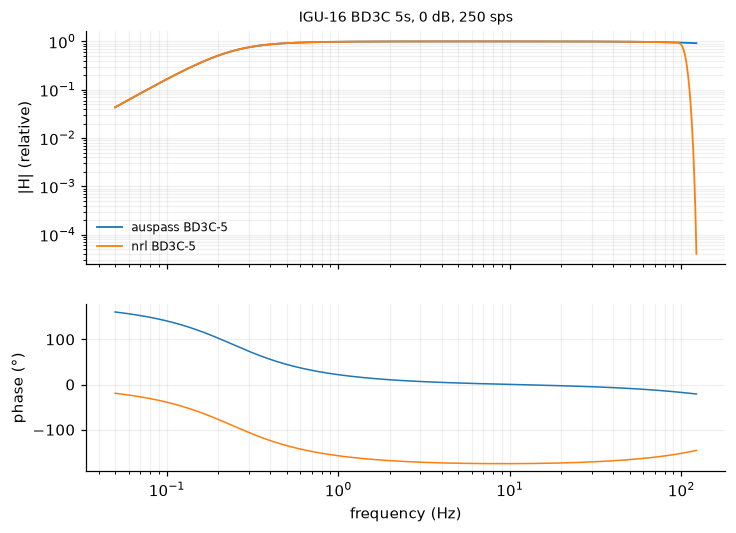

In [12]:
t, fig = sr.inspect_instrument_response({"auspass BD3C-5": "auspass", "nrl BD3C-5": "nrl"}, device_type="IGU-16 BD3C 5s",
                                       gain_db=0, sampling_rate=250, normalise=True)

## 8. Adding your own model
Any response can be added as a folder:
1. **Make the folder.** Create `instrument_responses/<name>/` with StationXML files and a `response.yaml` listing them (`file`, `device`, `gain_db`, and optionally `sample_rate`, `filter_phase`).
2. **Use it.** `sr.get_response("<name>", ...)` and `wf.build_inventory(sel, response="<name>")` pick it up, and so does `metadata.response: <name>` in a batch settings file.

`scripts/make_instrument_responses.py` rebuilds the shipped models and downloads the NRL files from the [EarthScope NRL web service](https://service.earthscope.org/irisws/nrl/1/).

## Summary
- **The default.** `auspass` (default) and `nrl` agree in the passband; both are built on the manufacturer's geophone, which huddle tests confirm.
- **Minimum-phase data.** Use `nrl` when the anti-alias filter matters: minimum-phase data, or work near Nyquist.
- **Preamp gain.** dB against powers of two is an open 0.2–1.4 % question at gains above 0 dB.
- **Temperature.** Through the coil resistance, the effect is about 1 % in sensitivity over −40 to +40 °C. The boot test measures each node at each power-up.